# CIFAR-10 Image Classification: TensorFlow vs PyTorch
Simple neural network (MLP) and CNN implemented in both frameworks with identical data, architecture and hyperparameters.



## Setup

In [1]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED, EPOCHS, BATCH, LR = 42, 10, 64, 1e-3
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
print("PyTorch:", torch.__version__, "| Device:", device)

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PyTorch: 2.11.0+cu130 | Device: cuda


## Data

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()

mean = x_train.mean(axis=(0, 1, 2)) / 255.0
std = x_train.std(axis=(0, 1, 2)) / 255.0
x_train = ((x_train / 255.0 - mean) / std).astype("float32")
x_test = ((x_test / 255.0 - mean) / std).astype("float32")

classes = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3209s 19us/step
(50000, 32, 32, 3) (50000,) (10000, 32, 32, 3) (10000,)


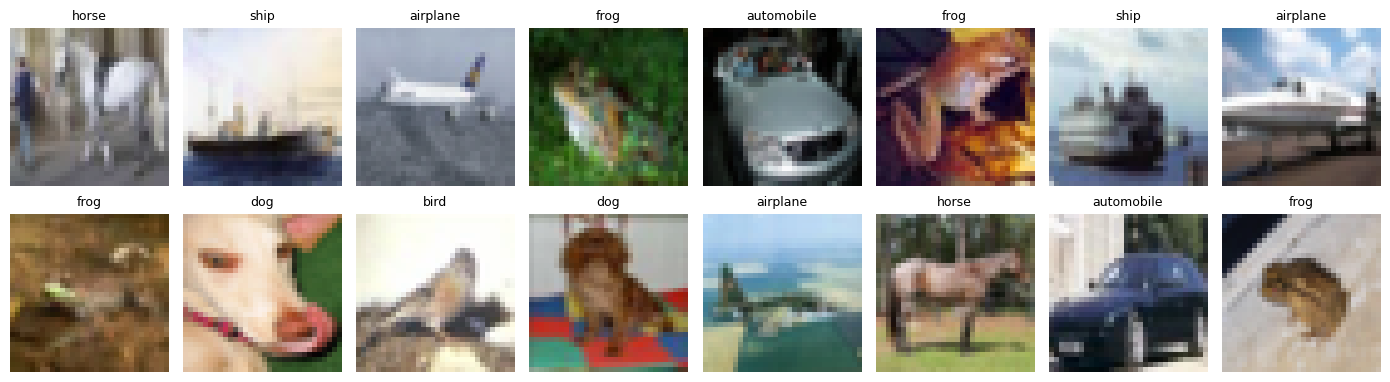

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.flat, np.random.choice(len(x_train), 16, replace=False)):
    ax.imshow(np.clip(x_train[i] * std + mean, 0, 1))
    ax.set_title(classes[y_train[i]], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [4]:
results, histories = [], {}

def record(framework, model, train_time, acc, hist):
    results.append({"Framework": framework, "Model": model, "Training time (s)": round(train_time, 1), "Test accuracy (%)": round(acc * 100, 2)})
    histories[f"{framework} {model}"] = hist

## TensorFlow helpers

In [5]:
def tf_train(model):
    model.compile(optimizer=tf.keras.optimizers.Adam(LR),
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=["accuracy"])
    start = time.time()
    h = model.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH,
                  validation_data=(x_test, y_test), verbose=2)
    train_time = time.time() - start
    _, acc = model.evaluate(x_test, y_test, verbose=0)
    return train_time, acc, h.history["val_accuracy"]

## PyTorch helpers

In [6]:
Xtr = torch.tensor(x_train).permute(0, 3, 1, 2).to(device)
Ytr = torch.tensor(y_train, dtype=torch.long).to(device)
Xte = torch.tensor(x_test).permute(0, 3, 1, 2).to(device)
Yte = torch.tensor(y_test, dtype=torch.long).to(device)

@torch.no_grad()
def pt_evaluate(model):
    model.eval()
    correct = sum((model(Xte[i:i + 1000]).argmax(1) == Yte[i:i + 1000]).sum().item() for i in range(0, len(Xte), 1000))
    return correct / len(Xte)

def pt_train(model):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()
    accs = []
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.time()
    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(Xtr), device=device)
        total_loss = 0.0
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            opt.step()
            total_loss += loss.item() * len(idx)
        accs.append(pt_evaluate(model))
        print(f"Epoch {epoch + 1}/{EPOCHS} - loss: {total_loss / len(Xtr):.4f} - val_accuracy: {accs[-1]:.4f}")
    if device.type == "cuda": torch.cuda.synchronize()
    train_time = time.time() - start
    return train_time, pt_evaluate(model), accs

## Task 1: Simple Neural Network – TensorFlow

In [7]:
tf_mlp = tf.keras.Sequential([
    tf.keras.layers.Input((32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10),
])
tf_mlp.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
t, acc, h = tf_train(tf_mlp)
record("TensorFlow", "Simple NN", t, acc, h)
print(f"\nTraining time: {t:.1f}s | Test accuracy: {acc * 100:.2f}%")

Epoch 1/10
782/782 - 8s - 10ms/step - accuracy: 0.3962 - loss: 1.7402 - val_accuracy: 0.4532 - val_loss: 1.5425
Epoch 2/10
782/782 - 5s - 7ms/step - accuracy: 0.4751 - loss: 1.4906 - val_accuracy: 0.4813 - val_loss: 1.4825
Epoch 3/10
782/782 - 2s - 3ms/step - accuracy: 0.5143 - loss: 1.3819 - val_accuracy: 0.4869 - val_loss: 1.4729
Epoch 4/10
782/782 - 3s - 4ms/step - accuracy: 0.5426 - loss: 1.2950 - val_accuracy: 0.4974 - val_loss: 1.4767
Epoch 5/10
782/782 - 5s - 6ms/step - accuracy: 0.5691 - loss: 1.2200 - val_accuracy: 0.4946 - val_loss: 1.5071
Epoch 6/10
782/782 - 3s - 3ms/step - accuracy: 0.5919 - loss: 1.1510 - val_accuracy: 0.5008 - val_loss: 1.5192
Epoch 7/10
782/782 - 2s - 3ms/step - accuracy: 0.6140 - loss: 1.0877 - val_accuracy: 0.4901 - val_loss: 1.5889
Epoch 8/10
782/782 - 3s - 4ms/step - accuracy: 0.6363 - loss: 1.0271 - val_accuracy: 0.4917 - val_loss: 1.6312
Epoch 9/10
782/782 - 5s - 6ms/step - accuracy: 0.6545 - loss: 0.9738 - val_accuracy: 0.4990 - val_loss: 1.7052


## Task 2: Simple Neural Network – PyTorch

In [9]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(32 * 32 * 3, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = torch.flatten(x, 1)
        return self.fc3(F.relu(self.fc2(F.relu(self.fc1(x)))))

pt_mlp = MLP()
print(pt_mlp, "\nParameters:", sum(p.numel() for p in pt_mlp.parameters()))

MLP(
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
) 
Parameters: 1707274


In [ ]:
t, acc, h = pt_train(pt_mlp)
record("PyTorch", "Simple NN", t, acc, h)
print(f"\nTraining time: {t:.1f}s | Test accuracy: {acc * 100:.2f}%")

## Task 3: CNN – TensorFlow

In [ ]:
L = tf.keras.layers
tf_cnn = tf.keras.Sequential([
    L.Input((32, 32, 3)),
    L.Conv2D(32, 3, padding="same", activation="relu"),
    L.Conv2D(32, 3, padding="same", activation="relu"),
    L.MaxPooling2D(),
    L.Conv2D(64, 3, padding="same", activation="relu"),
    L.Conv2D(64, 3, padding="same", activation="relu"),
    L.MaxPooling2D(),
    L.Flatten(),
    L.Dense(512, activation="relu"),
    L.Dropout(0.5),
    L.Dense(10),
])
tf_cnn.summary()

In [ ]:
t, acc, h = tf_train(tf_cnn)
record("TensorFlow", "CNN", t, acc, h)
print(f"\nTraining time: {t:.1f}s | Test accuracy: {acc * 100:.2f}%")

## Task 4: CNN – PyTorch (same architecture)

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 512), nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

pt_cnn = CNN()
print(pt_cnn, "\nParameters:", sum(p.numel() for p in pt_cnn.parameters()))
print("TensorFlow parameters:", tf_cnn.count_params())

In [ ]:
t, acc, h = pt_train(pt_cnn)
record("PyTorch", "CNN", t, acc, h)
print(f"\nTraining time: {t:.1f}s | Test accuracy: {acc * 100:.2f}%")

## Task 5: Comparison of Training Time and Accuracy

In [ ]:
df = pd.DataFrame(results)
df["Time / epoch (s)"] = (df["Training time (s)"] / EPOCHS).round(2)
df

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["Training time (s)", "Test accuracy (%)"]):
    piv = df.pivot(index="Model", columns="Framework", values=col).loc[["Simple NN", "CNN"]]
    piv.plot(kind="bar", ax=ax, rot=0, color=["#ee4c2c", "#ff8f00"])
    ax.set_title(col); ax.set_xlabel("")
    for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
plt.figure(figsize=(8, 4.5))
for name, accs in histories.items():
    plt.plot(range(1, EPOCHS + 1), np.array(accs) * 100, marker="o", ls="--" if "PyTorch" in name else "-", label=name)
plt.xlabel("Epoch"); plt.ylabel("Test accuracy (%)"); plt.title("Test accuracy per epoch")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
for m in ["Simple NN", "CNN"]:
    tf_r = df[(df.Framework == "TensorFlow") & (df.Model == m)].iloc[0]
    pt_r = df[(df.Framework == "PyTorch") & (df.Model == m)].iloc[0]
    faster = "TensorFlow" if tf_r["Training time (s)"] < pt_r["Training time (s)"] else "PyTorch"
    ratio = max(tf_r["Training time (s)"], pt_r["Training time (s)"]) / min(tf_r["Training time (s)"], pt_r["Training time (s)"])
    better = "TensorFlow" if tf_r["Test accuracy (%)"] > pt_r["Test accuracy (%)"] else "PyTorch"
    gap = abs(tf_r["Test accuracy (%)"] - pt_r["Test accuracy (%)"])
    print(f"{m}: {faster} trained {ratio:.2f}x faster; {better} was more accurate by {gap:.2f} percentage points.")
for f in ["TensorFlow", "PyTorch"]:
    s = df[df.Framework == f].set_index("Model")
    print(f"{f}: CNN improved accuracy over Simple NN by {s.loc['CNN', 'Test accuracy (%)'] - s.loc['Simple NN', 'Test accuracy (%)']:.2f} points.")

## Task 6: Discussion

**Performance.** Both frameworks were trained under the same conditions (same normalised data, architectures, Adam at lr = 0.001, batch size 64, 10 epochs, same GPU), so the differences above come from the frameworks themselves. Final accuracies are close for each model type; small gaps (typically 1–2 points) are expected because the frameworks use different default weight initialisations (Glorot-uniform in Keras, Kaiming-uniform in PyTorch) and different random streams for shuffling and dropout. The architecture matters far more than the framework: the CNN beats the simple network by a wide margin in both, because convolutions exploit the spatial structure of images while the MLP flattens each image and loses it. The MLP also plateaus quickly and begins to overfit, while the CNN keeps improving.

Training-time differences reflect each framework's execution model. Keras compiles `fit()` into a TensorFlow graph, which removes Python overhead per step; this tends to help small, fast models like the MLP, where per-batch overhead dominates. PyTorch runs eagerly, launching operations from Python each step, but cuDNN does most of the work for convolutions, so the gap usually narrows for the CNN. Keeping the full dataset on the GPU in PyTorch removed data-loading as a factor; with a standard `DataLoader` the PyTorch time would be higher.

**Ease of implementation.** TensorFlow/Keras needed less code: `compile()`, `fit()` and `evaluate()` handle the training loop, batching, metrics, validation and progress logging, and `summary()` reports output shapes and parameter counts automatically. PyTorch required a hand-written training loop (zeroing gradients, forward pass, loss, backward pass, optimiser step), manual accuracy calculation, explicit device placement, and conversion from NHWC to NCHW tensor layout. It also needed the input size of the first linear layer (64 × 8 × 8) worked out by hand, whereas Keras infers it. In exchange, PyTorch gives full, visible control over every step, which makes custom training logic straightforward.

**Debugging experience.** PyTorch was easier to debug. Because it executes eagerly, errors such as shape mismatches are raised at the exact line in `forward()`, and intermediate tensors can be printed or inspected with ordinary Python tools. In Keras, problems inside `fit()` surface as long tracebacks from inside the compiled graph, which are harder to trace back to the cause; shape errors are, however, often caught earlier, when the model is built, thanks to the `Input` layer.

**Conclusion.** Both frameworks reach comparable accuracy on identical architectures. TensorFlow/Keras is quicker to write and well suited to standard workflows, while PyTorch offers more transparency and control and a smoother debugging experience. For this task, model choice (CNN over MLP) has a much larger impact on accuracy than framework choice.